# Exercise 2 - Chapter 2
**Julian Barth**
## Emulsion Polymerisation

**Assumptions & Governing Equations:**
* **Seeded Emulsion:** We assume a 0-1 system where the average number of radicals per particle is $\bar{n} = 0.5$.
* **Volume:** The total suspension volume is constant at $V_{sus} = 10$. The monomer dissolved in the water phase is .
* **Langmuir Adsorption:** Emulsifier adsorption follows the Langmuir isotherm (Equations 2.8 and 2.9).
* **Phases:** The system consists of Interval II (constant monomer volume fraction in particles, $\phi_M^* = 0.5$, while droplets exist) and Interval III (droplets depleted, $\phi_M$ decreases).

## 1) 
### preliminary calculation of seed mass and number


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
%config InlineBackend.figure_format = 'retina'


# Constants
V_sus = 10.0          # L
d0_pol = 50e-9        # m
M0_conc = 2.0         # mol/L (relative to suspension volume)
w_I0 = 0.01           # mass fraction initiator monomer
w_pol_seeds = 0.05    # weight fraction of unswollen seeds entire mixture

M_mM = 100.0          # g/mol
M_mI = 164.0          # g/mol
phi_M_star = 0.5      # volume fraction of monomer in particles
rho_pol = 1.10        # kg/L
rho_M = 0.94          # kg/L
rho_w = 1.00          # kg/L

kp = 715.0            # L/(mol s)
N_A = 6.022e23        # 1/mol
cmc = 40e-3           # mol/L
a_E = 50e-20          # m^2 (50 Angstrom^2)
K_E = 100.0           # L/mol

# Initial System Balances
# Monomer added
m_M = M0_conc * V_sus * (M_mM / 1000)  # kg (20 mol * 100 g/mol)
m_I = w_I0 * m_M                       # kg


#### peut etre une bonne idee de le faire en mardown avant. 
# We know: m_pol = 0.05 * m_tot
# V_sus = V_w + V_pol + V_M = m_w/rho_w + m_pol/rho_pol + m_M/rho_M // assume initiator negligeable
# Solving the system algebraically for m_pol and m_w:
# m_tot = m_w + m_pol + m_M + m_I 
# m_w = (1/0.05 * m_pol - m_pol) - m_M - m_I
# 10 = ((19 * m_pol) - m_M - m_I)/1.0 + m_pol/1.10 + m_M/0.94 

term1 = 10 - m_M/rho_M + (m_M + m_I)/rho_w
m_pol = term1 / (19.0/rho_w + 1.0/rho_pol)
m_w = 19 * m_pol - m_M - m_I
m_tot = m_w + m_pol + m_M + m_I

# Seed particle characteristics
v_p0 = (np.pi / 6) * (d0_pol * 10) ** 3  # L (converting m to dm/L)
m_p0 = v_p0 * rho_pol                    # kg
N_p = m_pol / m_p0                       # Total number of particles
N_p_vol = N_p / V_sus                    # Particles per L of suspension

print(f"Total Mass: {m_tot:.2f} kg, Water Mass: {m_w:.2f} kg, Polymer Mass: {m_pol:.3f} kg")
print(f"Total Number of Seed Particles (N_p): {N_p:.3e}")

Total Mass: 9.94 kg, Water Mass: 7.42 kg, Polymer Mass: 0.497 kg
Total Number of Seed Particles (N_p): 6.902e+18


### a) maximum emulsifier concentration

In [5]:
# To avoid secondary nucleation, the free emulsifier must not exceed the CMC.
E_w = cmc

# Surface area of a single seed particle (s_p)
s_p = np.pi * (d0_pol)**2  # m^2

# Surface area of the particles per unit volume (a_p)
a_p = (N_p * s_p) / V_sus  # m^2 / L

# Saturation concentration of adsorbed emulsifier (Eq 2.9)
Gamma_E_inf = a_p / (a_E * N_A)  # mol / L

# Adsorbed emulsifier concentration using Langmuir isotherm (Eq 2.8)
Gamma_E = Gamma_E_inf * ((K_E * E_w) / (1 + K_E * E_w))  # mol / L

# In the mass balance E_0 = E_w + E_p + E_M (with E_M negligible), 
# E_p is the adsorbed concentration (Gamma_E).
E_p = Gamma_E
E_0 = E_w + E_p

print(f"Q1a: Maximum total emulsifier concentration (E_0) = {E_0:.4f} mol/L")

Q1a: Maximum total emulsifier concentration (E_0) = 0.0544 mol/L


The calculated maximum total emulsifier ($E_0 \approx 0.0544$ mol/L) exceeds the CMC ($0.040$ mol/L). This is physically consistent because the CMC solely dictates the upper limit of the *free* aqueous emulsifier concentration ($E_w$). A substantial portion of the total added emulsifier ($E_p \approx 0.0144$ mol/L) adsorbs onto the large surface area of the existing polymer. Micelle formation, and thus secondary nucleation, will only occur if $E_0$ exceeds the sum of this saturation adsorption and the CMC.

### b) Largest Particle Size

In [9]:
# The swollen particle reaches its maximum volume precisely when the monomer droplets are fully depleted.
# At this point, all remaining monomer is inside the particles, and phi = 0.5.
# Volume of polymer = Volume of monomer

# V_pol = (m_pol + X * m_M) / rho_pol
# V_mon = ((1 - X) * m_M) / rho_M
# Equating V_pol and V_mon to find conversion X at depletion:
# (m_pol + X * m_M)/rho_pl = ((1 - X) * m_M)/rho_m

def find_depletion_conversion():
    # Solving A + B*X = C - C*X -> X(B + C) = C - A
    A = m_pol / rho_pol
    B = m_M / rho_pol
    C = m_M / rho_M
    return (C - A) / (B + C)

X_depletion = find_depletion_conversion()

# Volumes at depletion
V_pol_max = (m_pol + X_depletion * m_M) / rho_pol
V_mon_max = ((1 - X_depletion) * m_M) / rho_M
V_p_tot_max = V_pol_max + V_mon_max  # Total swollen volume

v_p_max = V_p_tot_max / N_p  # Volume of a single swollen particle in L
d_max_dm = ( (6 * v_p_max) / np.pi ) ** (1/3) # dm
d_max_nm = d_max_dm * 1e8 # converting dm to nm

print(f"Conversion at droplet depletion: {X_depletion:.3f}")
print(f"Q1b: Largest particle diameter during reaction = {d_max_nm:.2f} nm")

Conversion at droplet depletion: 0.425
Q1b: Largest particle diameter during reaction = 87.82 nm


### c) minimum emulsifier concentration

In [12]:
# Minimum required coverage is Gamma_E / Gamma_inf = 0.2
theta_min = 0.2

# Find required E_w for this coverage using Langmuir
# 0.2 = (K_E * E_w) / (1 + K_E * E_w) -> E_w = 0.2 / (0.8 * K_E)
E_w_min = theta_min / ((1 - theta_min) * K_E)

# Calculate saturation adsorption at the maximum particle size
S_tot_max = N_p * np.pi * (d_max_nm * 1e-9)**2
n_E_inf_max = S_tot_max / (a_E * N_A)
Gamma_inf_max = n_E_inf_max / V_sus

E_p_min = theta_min * Gamma_inf_max
E_0_min = E_w_min + E_p_min

print(f"Q1c: Minimum total emulsifier concentration (E_0_min) = {E_0_min:.4f} mol/L")

Q1c: Minimum total emulsifier concentration (E_0_min) = 0.0136 mol/L


The minimum emulsifier required must be calculated at the point of maximum surface area (Interval II/III transition) to ensure the particles remain stable throughout the entire reaction lifecycle. The Langmuir isotherm algebraically dictates the exact aqueous equilibrium concentration necessary to sustain 20% surface coverage.

## 2) Kinetics Simulation & Plotting

<>:78: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:78: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
/var/folders/x8/ypxvp3g937zfhl5gj7l0_7vm0000gn/T/ipykernel_25343/174993032.py:78: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  axs[1,1].set_ylabel('Monomer Vol Fraction in Particles, $\phi$')


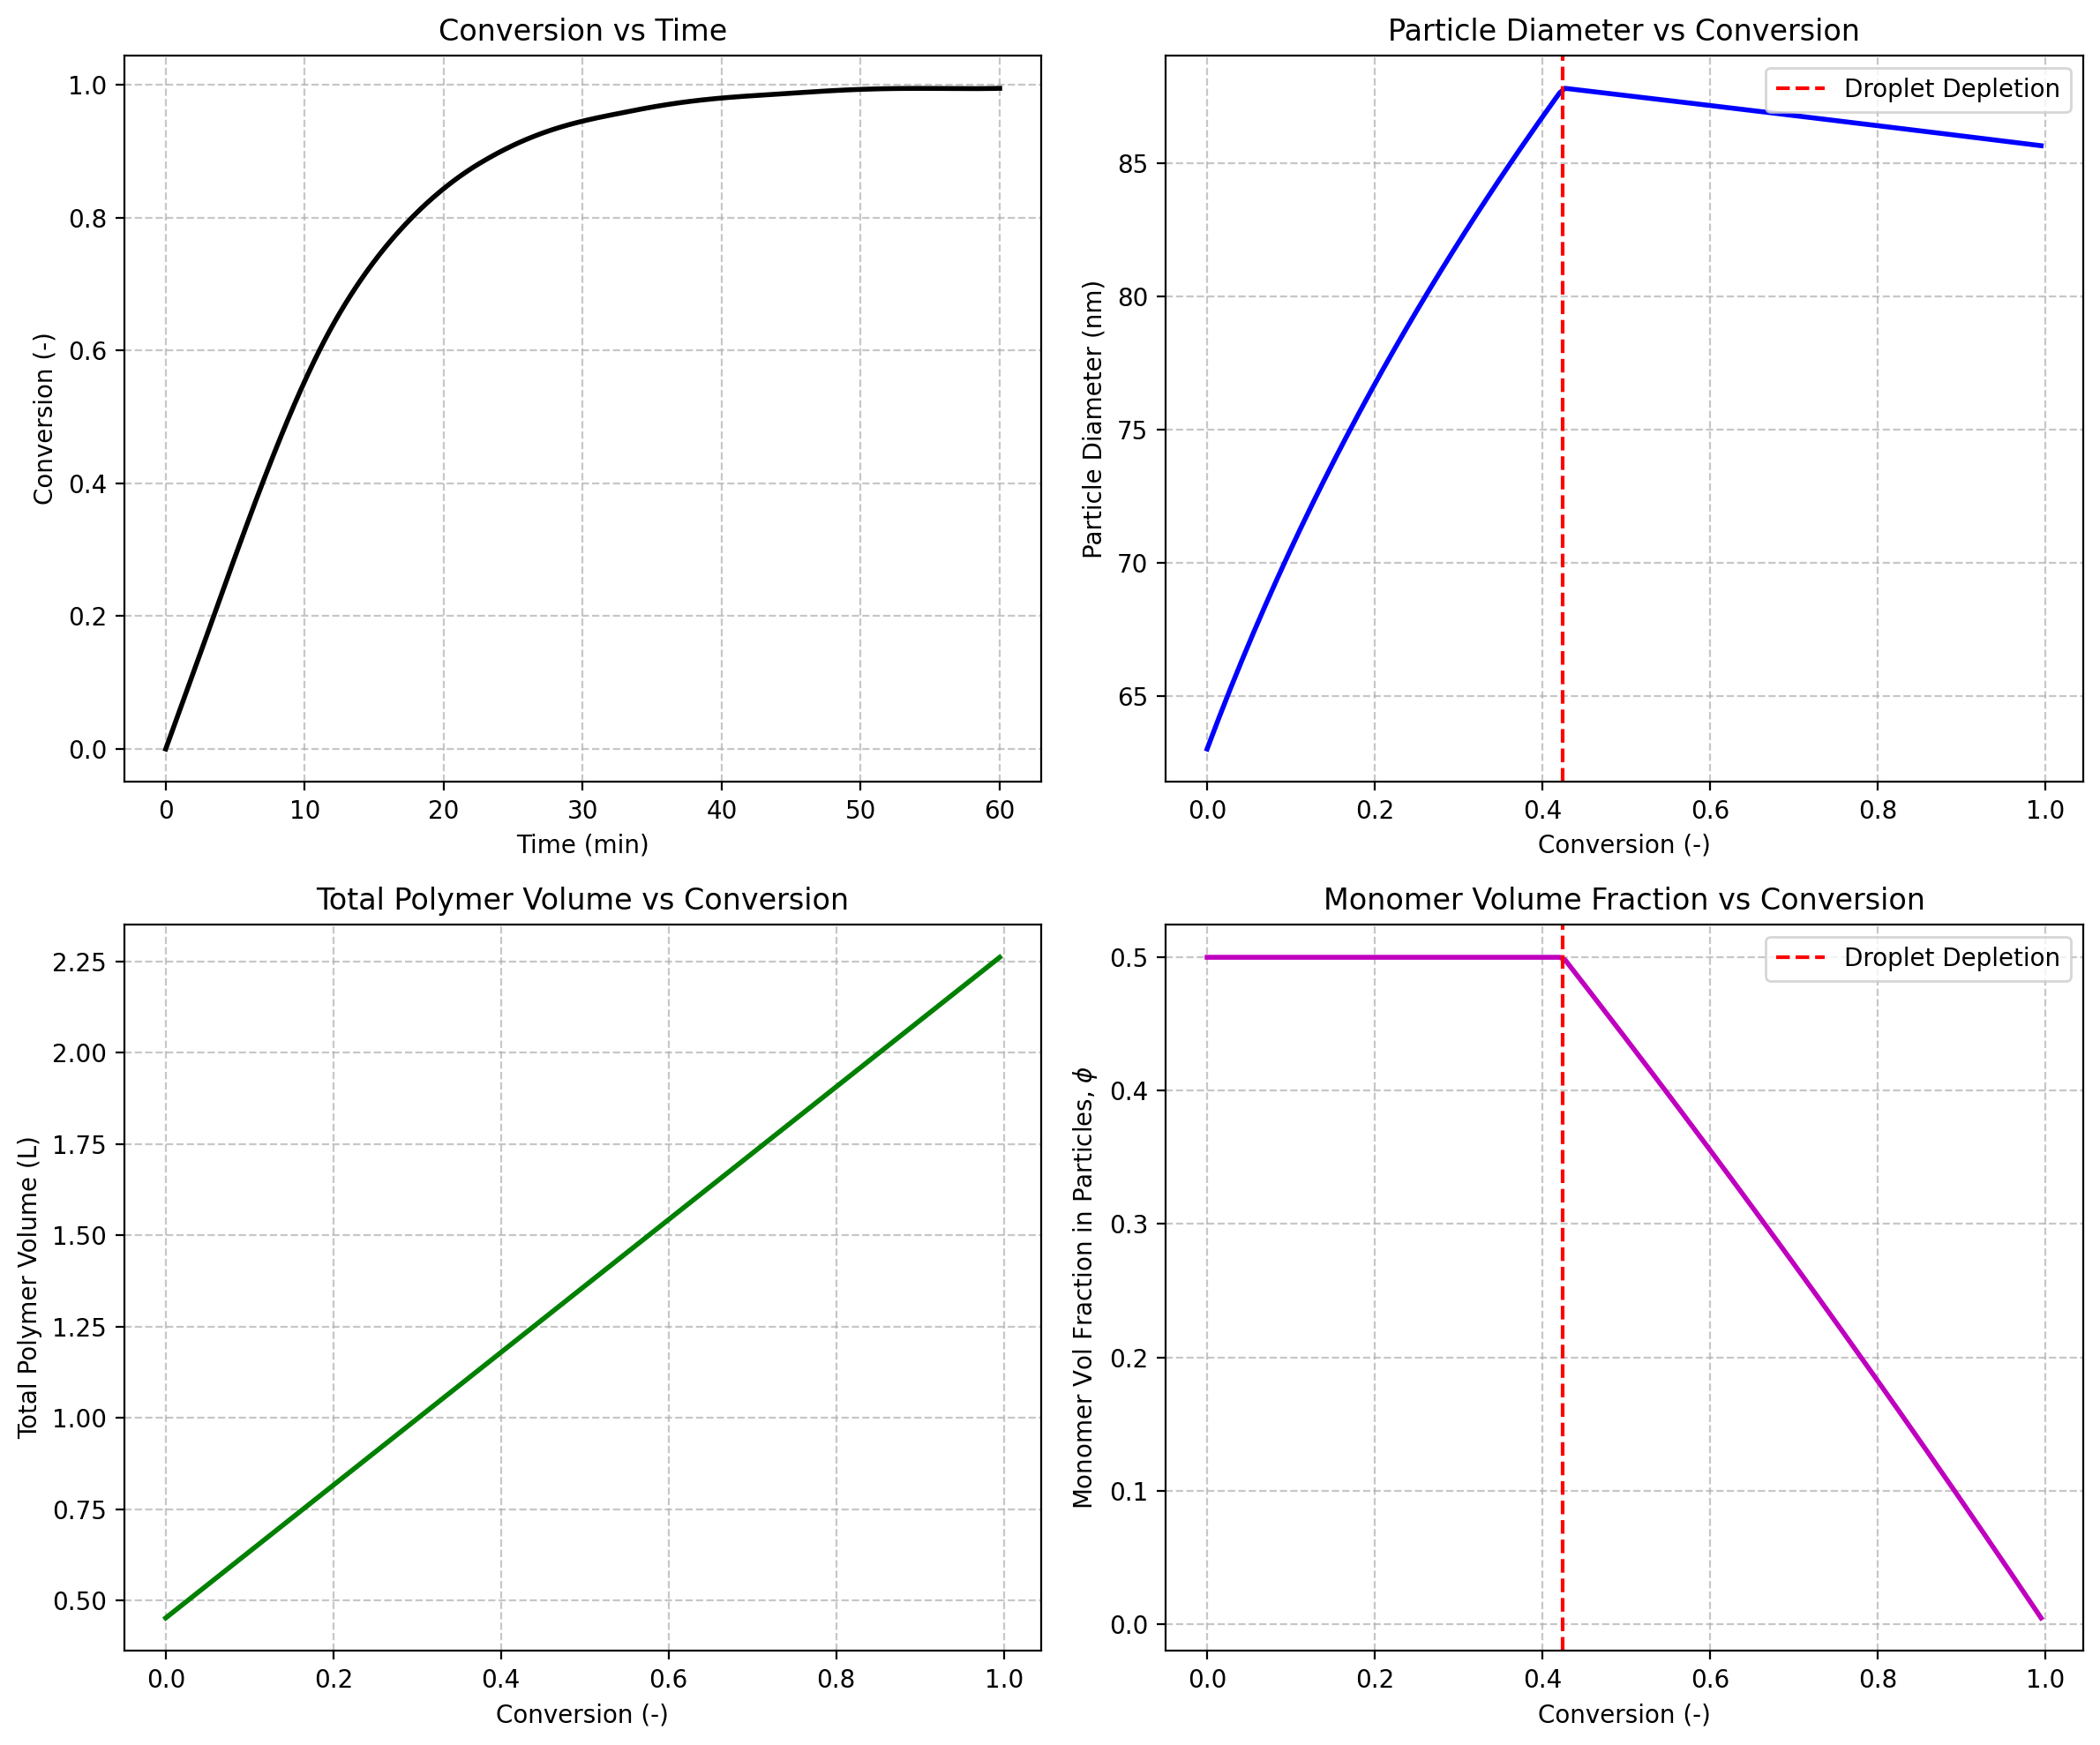

In [13]:
total_monomer_moles = M0_conc * V_sus

def kinetics(t, X): #
    x = X[0]
    if x >= 1.0:
        return [0.0]
    
    if x <= X_depletion:
        # Interval II: constant phi
        phi = phi_M_star
    else:
        # Interval III: phi decreases
        V_mon = ((1 - x) * m_M) / rho_M
        V_pol = (m_pol + x * m_M) / rho_pol
        phi = V_mon / (V_mon + V_pol)
    
    # Monomer concentration in the particle
    M_p = phi * (rho_M * 1000) / M_mM  # mol/L
    
    # Rate of reaction: dx/dt = (kp * M_p * n_bar * N_p) / (N_A * total_moles)
    # n_bar = 0.5 for a 0-1 system
    dx_dt = (kp * M_p * 0.5 * N_p) / (N_A * total_monomer_moles)
    return [dx_dt]

# Integrate ODE
t_span = (0, 3600)  # 1 hour simulation
sol = solve_ivp(kinetics, t_span, [0.0], t_eval=np.linspace(0, 3600, 500))

time = sol.t
conversion = sol.y[0]

# Calculate variables over conversion
phi_arr = np.zeros_like(conversion)
diam_arr = np.zeros_like(conversion)
V_pol_arr = np.zeros_like(conversion)

for i, x in enumerate(conversion):
    V_pol = (m_pol + x * m_M) / rho_pol
    V_mon = ((1 - x) * m_M) / rho_M if x <= X_depletion else ((1 - x) * m_M) / rho_M
    
    if x <= X_depletion:
        phi_arr[i] = phi_M_star
        V_p_tot = V_pol / (1 - phi_M_star)
    else:
        V_p_tot = V_pol + V_mon
        phi_arr[i] = V_mon / V_p_tot
        
    v_p_single = V_p_tot / N_p
    diam_arr[i] = ( (6 * v_p_single) / np.pi )**(1/3) * 1e8 # converting dm to nm
    V_pol_arr[i] = V_pol

# Plotting
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

axs[0,0].plot(time / 60, conversion, 'k-', linewidth=2)
axs[0,0].set_xlabel('Time (min)')
axs[0,0].set_ylabel('Conversion (-)')
axs[0,0].set_title('Conversion vs Time')
axs[0,0].grid(True, linestyle='--', alpha=0.7)

axs[0,1].plot(conversion, diam_arr, 'b-', linewidth=2)
axs[0,1].axvline(X_depletion, color='r', linestyle='--', label='Droplet Depletion')
axs[0,1].set_xlabel('Conversion (-)')
axs[0,1].set_ylabel('Particle Diameter (nm)')
axs[0,1].set_title('Particle Diameter vs Conversion')
axs[0,1].legend()
axs[0,1].grid(True, linestyle='--', alpha=0.7)

axs[1,0].plot(conversion, V_pol_arr, 'g-', linewidth=2)
axs[1,0].set_xlabel('Conversion (-)')
axs[1,0].set_ylabel('Total Polymer Volume (L)')
axs[1,0].set_title('Total Polymer Volume vs Conversion')
axs[1,0].grid(True, linestyle='--', alpha=0.7)

axs[1,1].plot(conversion, phi_arr, 'm-', linewidth=2)
axs[1,1].axvline(X_depletion, color='r', linestyle='--', label='Droplet Depletion')
axs[1,1].set_xlabel('Conversion (-)')
axs[1,1].set_ylabel('Monomer Vol Fraction in Particles, $\phi$')
axs[1,1].set_title('Monomer Volume Fraction vs Conversion')
axs[1,1].legend()
axs[1,1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

The plots illustrate the two distinct kinetic regimes dictated by Smith-Ewart kinetics. In Interval II, the monomer volume fraction $\phi$ remains constant at $0.5$ due to monomer droplet partitioning, leading to linear growth in particle diameter and a constant reaction rate (linear conversion over time). Once droplets deplete, we enter Interval III: the conversion rate progressively drops, $\phi$ decays toward zero, and the particle diameter slightly contracts as low-density monomer converts into higher-density polymer.